# priora example figures — a ~90% NEO and a ~90% main-belt asteroid

Six **separate** figures, for the paper, poster and talk:

| view | what it shows |
|---|---|
| **hypothesis space** | posterior density over the admissible region in (ρ, ρ̇), with the true (ρ, ρ̇) and the q = 1.3 AU contour |
| **orbit space** | every node redrawn at the (q, e) of the orbit it implies, coloured by which population register holds objects there |
| **distance posterior** | the posterior collapsed onto ρ alone, with the true ρ |

for two objects:

* a **true NEO** with P(NEO) ≈ 0.90
* a **true main-belt asteroid** with P(NEO) ≈ 0.10, i.e. ≈ 90% likely *not* a NEO

**Where the objects come from.** Both are drawn from the stored v0 self-consistency gate population
(`validation/output/gate_v0/gen.npz`): 20,000 objects sampled from the classifier's own population
model, the set the calibration results in `validation/GATE_RESULTS.md` are measured on. The gate
observed them from the geocentre; here each object's stored orbit, H and epoch are **re-observed from
the Rubin site (obscode X05)** and re-scored. The pick is a printed, deterministic rule
(closest score to the target), not a hand choice.

**Run it top to bottom.** Every number on a figure is printed beside it, and the notebook *asserts*
the bookkeeping (Λ, P(NEO), mass normalisation, truth inside the admissible region), so a
failed check stops the run instead of producing a silently wrong figure. Run with the Rubin-stack
kernel: `/opt/rubin/stack/conda/envs/lsst-scipipe-12.1.0/bin/python3`.

## 1. Configuration and provenance

In [1]:
import json, hashlib, subprocess
from pathlib import Path

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from astropy.time import Time

import priora
from priora import Attributable, Digest2Histogram, classify
from priora.attributable import observer_state
from priora.transforms import (observables_from_elements, topocentric_to_heliocentric,
                             state_equ_to_ecl, elements_from_state)

# --- paths (the notebook lives in paper/figures/) -------------------------
REPO = Path.cwd().resolve().parents[1]           # .../priora
OUT = Path.cwd().resolve()                       # figures are written next to the notebook
GATE = REPO / "validation/output/gate_v0"
MODEL = REPO / "data/digest2.model.csv"

# --- science configuration -------------------------------------------------
OBSCODE = "X05"                 # Simonyi Survey Telescope, Rubin Observatory
VARIANT = "All"                 # D-10: keep All
H_EXTEND_TO = 30.0              # D-19 canonical value (recommended for production)
N_RHO, N_RHODOT = 1200, 50      # production grid (classify defaults)
RHO_MIN, RHO_MAX = 0.01, 100.0  # classify defaults
V_LIM = 24.0                    # same visibility cut as the gate
TARGET = {"NEO": 0.90, "MBA": 0.10}
# main-belt definition for the MBA pick (gate 'other' also holds Mars-crossers, Hildas, Trojans...)
MBA_A, MBA_QMIN = (2.1, 3.3), 1.66

# --- figure configuration ----------------------------------------------------
# Figure sizes in inches. At these sizes and fonts a figure reads well on a slide or poster and
# scales cleanly to a journal column (LaTeX: \\includegraphics[width=\\columnwidth]{...}).
SIZE = {"hypothesis": (6.6, 4.4), "orbit": (5.6, 4.6), "distance": (6.2, 3.4)}
PNG_DPI = 400                   # PNGs for slides/poster
PDF_RASTER_DPI = 600            # the density layer inside the PDF is rasterised at this dpi
SHARE_AXES = False              # True: NEO and MBA figures use identical axis ranges (for side-by-side)
ANNOTATE = True                 # print P(NEO) etc. inside each figure (handy for talks)

# --- provenance --------------------------------------------------------------
def git(*a):
    return subprocess.run(["git", "-C", str(REPO), *a], capture_output=True, text=True).stdout.strip()
COMMIT = git("rev-parse", "--short", "HEAD")
DIRTY = bool(git("status", "--porcelain", "--", "src", "rust", "data"))
MODEL_SHA = hashlib.sha256(MODEL.read_bytes()).hexdigest()
print(f"priora commit {COMMIT}{' (DIRTY src/rust/data!)' if DIRTY else ''}")
print(f"priora.__version__ = {priora.__version__}   (may lag the checkout; trust the commit)")
print(f"model {MODEL.name}  sha256 {MODEL_SHA[:16]}…")
print(f"observer {OBSCODE}, variant {VARIANT}, h_extend_to {H_EXTEND_TO}, grid {N_RHO}x{N_RHODOT}")

priora commit a4bc848
priora.__version__ = 0.0.1.dev44+unknown.gf4d6b88ca.d20260908   (may lag the checkout; trust the commit)
model digest2.model.csv  sha256 2b9d9d2a6d8ab16d…
observer X05, variant All, h_extend_to 30.0, grid 1200x50


## 2. Load the gate population and check the stored geometry

Re-observing from Rubin is only legitimate if the stored elements really are the objects' elements
*at the observation epoch*. Check: the stored elements + the stored geocentric observer must reproduce
the stored geocentric tracklets exactly.

In [2]:
gen = np.load(GATE / "gen.npz")
sc = np.load(GATE / "scores.npz")
assert (sc["index"] == np.arange(len(sc["index"]))).all()

el, H = gen["elements"], gen["H"]
chk = observables_from_elements(el, H, gen["R_obs"], gen["V_obs"])
d_ra = np.abs((chk["ra"] - gen["ra"] + np.pi) % (2 * np.pi) - np.pi).max()
d_dec = np.abs(chk["dec"] - gen["dec"]).max()
d_v = np.abs(chk["v_mag"] - gen["v_mag"]).max()
print(f"max |Δra| = {d_ra:.1e} rad, max |Δdec| = {d_dec:.1e} rad, max |ΔV| = {d_v:.1e} mag")
assert max(d_ra, d_dec, d_v) < 1e-10, "stored geometry does not reproduce -- do not re-observe"

a, e = el[:, 0], el[:, 1]
q = a * (1 - e)
is_neo = gen["is_neo"].astype(bool)
is_mba = (~is_neo) & (a > MBA_A[0]) & (a < MBA_A[1]) & (q > MBA_QMIN)
print(f"{len(a):,} gate objects: {is_neo.sum()} true NEOs, {is_mba.sum():,} main-belt by the definition above")

max |Δra| = 8.9e-16 rad, max |Δdec| = 2.5e-16 rad, max |ΔV| = 3.6e-15 mag
20,000 gate objects: 185 true NEOs, 17,035 main-belt by the definition above


## 3. Re-observe from Rubin and select the two objects

Pre-filter on the stored (geocentric) gate score to a generous window around each target, re-observe every
candidate from X05, re-score, and keep the candidate whose **Rubin-site** score is closest to the target.
Candidates that fall above V = 24 from the Rubin site are dropped (same cut as the gate). Takes ~15 s.

In [3]:
neo_pop, other_pop = Digest2Histogram.neo_other_pair(str(MODEL), variant=VARIANT, h_extend_to=H_EXTEND_TO)

def observe(k):
    # Re-observe gate object k from OBSCODE. Returns (attributable, R_obs, V_obs, truth dict).
    t = Time(gen["epoch_jd_tdb"][k], format="jd", scale="tdb")
    R, V = observer_state(t, obscode=OBSCODE)
    o = {kk: float(np.asarray(v)) for kk, v in observables_from_elements(el[k], np.array(H[k]), R, V).items()}
    att = Attributable(ra=o["ra"], dec=o["dec"], ra_rate=o["ra_rate"], dec_rate=o["dec_rate"],
                       epoch=t, v_mag=o["v_mag"])
    return att, R, V, o

def score(k, diagnostics=False):
    att, R, V, o = observe(k)
    res = classify(att, neo_pop, other_pop, R_obs=R, V_obs=V, n_rho=N_RHO, n_rhodot=N_RHODOT,
                   rho_min=RHO_MIN, rho_max=RHO_MAX, diagnostics=diagnostics)
    return res, att, R, V, o

windows = {"NEO": is_neo & (sc["p_neo"] > 0.6) & (sc["p_neo"] < 0.99),
           "MBA": is_mba & (sc["p_neo"] > 0.01) & (sc["p_neo"] < 0.4)}
PICK = {}
for lab, mask in windows.items():
    rows = []
    for k in np.flatnonzero(mask):
        res, att, R, V, o = score(k)
        if o["v_mag"] <= V_LIM and np.isfinite(res.p_neo):
            rows.append((abs(res.p_neo - TARGET[lab]), int(k), res.p_neo, sc["p_neo"][k]))
    rows.sort()
    PICK[lab] = rows[0][1]
    print(f"{lab}: {mask.sum()} candidates, {len(rows)} visible from {OBSCODE}; closest to {TARGET[lab]}:")
    for _, k, px, pg in rows[:5]:
        print(f"   gate #{k:5d}  P(NEO) X05 {px:.4f}  (geocentric gate {pg:.4f})   "
              f"a={a[k]:.3f} e={e[k]:.3f} i={np.degrees(el[k,2]):5.1f}° q={q[k]:.3f} H={H[k]:.2f}")
print("\nPICK =", PICK)

NEO: 20 candidates, 20 visible from X05; closest to 0.9:
   gate # 5679  P(NEO) X05 0.8940  (geocentric gate 0.8948)   a=2.349 e=0.541 i= 10.7° q=1.078 H=23.29
   gate # 1096  P(NEO) X05 0.9160  (geocentric gate 0.9173)   a=2.561 e=0.493 i= 30.0° q=1.299 H=18.19
   gate #10863  P(NEO) X05 0.8551  (geocentric gate 0.8483)   a=2.889 e=0.574 i= 15.0° q=1.229 H=18.13
   gate #10749  P(NEO) X05 0.9504  (geocentric gate 0.9503)   a=2.209 e=0.528 i= 35.7° q=1.043 H=15.60
   gate #13460  P(NEO) X05 0.9524  (geocentric gate 0.9455)   a=1.389 e=0.390 i=  8.0° q=0.848 H=20.68


MBA: 199 candidates, 199 visible from X05; closest to 0.1:
   gate # 1247  P(NEO) X05 0.1039  (geocentric gate 0.1067)   a=2.885 e=0.353 i= 37.8° q=1.865 H=16.64
   gate # 7185  P(NEO) X05 0.0807  (geocentric gate 0.0783)   a=2.708 e=0.253 i= 35.7° q=2.023 H=18.13
   gate # 2534  P(NEO) X05 0.1201  (geocentric gate 0.1200)   a=2.502 e=0.327 i= 14.1° q=1.684 H=20.58
   gate #15917  P(NEO) X05 0.0778  (geocentric gate 0.0801)   a=2.495 e=0.241 i= 30.9° q=1.894 H=19.27
   gate #14445  P(NEO) X05 0.1310  (geocentric gate 0.1312)   a=3.187 e=0.399 i= 34.9° q=1.916 H=18.53

PICK = {'NEO': 5679, 'MBA': 1247}


## 4. Per-node quantities, with the bookkeeping asserted

For each object: classify on the production grid with diagnostics, then per node

* implied orbit (a, e, i) from the node's (ρ, ρ̇) — same transform chain the library uses — and the library's own `node_q`, `node_H`
* posterior **mass** m = (n_NEO|J| + n_other|J|) · weight, normalised to 1
* **register**: NEO if n_NEO > 0, other if n_other > 0, neither otherwise (v0's two registers partition at q = 1.3 AU, so never both)
* each node's **cell** in the plane: ρ edges are the geometric midpoints between the log-spaced ρ nodes (as in `ranging.build_grid`), ρ̇ edges are the midpoint-rule cell of width dρ̇ = weight / dρ

The hypothesis-space map is shaded by **dP / (d ln ρ dρ̇)** — probability per unit *displayed* area on a
log-ρ axis — so colour × visible area is probability. (Shading by raw per-node mass would make wide
cells look heavy.)

In [4]:
def analyse(lab):
    k = PICK[lab]
    res, att, R, V, o = score(k, diagnostics=True)
    g = res.grid
    K = res.grid.n_rhodot
    # --- grid structure: blocks of K nodes per rho column, rho_dot ascending
    assert g.rho.size % K == 0
    col_rho = g.rho[::K]
    assert np.all(g.rho.reshape(-1, K) == col_rho[:, None])
    assert np.all(np.diff(g.rho_dot.reshape(-1, K), axis=1) > 0)

    # --- rho cell edges, rebuilt exactly as ranging.build_grid does
    nodes = np.geomspace(RHO_MIN, RHO_MAX, N_RHO)
    edges = np.empty(N_RHO + 1); edges[0], edges[-1] = RHO_MIN, RHO_MAX
    edges[1:-1] = np.sqrt(nodes[:-1] * nodes[1:])
    j = np.searchsorted(nodes, col_rho * (1 - 1e-12))
    assert np.allclose(nodes[j], col_rho, rtol=1e-12, atol=0), "rho columns do not match the grid"
    lo_e, hi_e = np.repeat(edges[j], K), np.repeat(edges[j + 1], K)
    d_rho, d_lnrho = hi_e - lo_e, np.log(hi_e / lo_e)
    d_rhodot = g.weight / d_rho
    spacing = np.diff(g.rho_dot.reshape(-1, K), axis=1)
    assert np.allclose(spacing, d_rhodot.reshape(-1, K)[:, :-1], rtol=1e-8), "rho_dot cells inconsistent"

    # --- the bookkeeping: library's lambdas and p_neo reproduced from per-node arrays
    lam_n = np.sum(res.node_density_neo * g.weight)
    lam_o = np.sum(res.node_density_other * g.weight)
    assert np.isclose(lam_n, res.lambda_neo, rtol=1e-9) and np.isclose(lam_o, res.lambda_other, rtol=1e-9)
    assert np.isclose(lam_n / (lam_n + lam_o), res.p_neo, rtol=1e-12)
    assert not np.any((res.node_density_neo > 0) & (res.node_density_other > 0)), "registers overlap"

    mass = (res.node_density_neo + res.node_density_other) * g.weight
    mass = mass / mass.sum()
    dens = mass / (d_lnrho * d_rhodot)             # dP / (d ln rho  d rho_dot)
    assert np.isclose(np.sum(dens * d_lnrho * d_rhodot), 1.0)

    # --- implied orbit at every node (e and i are not stored by the library)
    n = g.rho.size
    r_e, v_e = topocentric_to_heliocentric(np.full(n, att.ra), np.full(n, att.dec), np.full(n, att.ra_rate),
                                           np.full(n, att.dec_rate), g.rho, g.rho_dot, R, V)
    E = elements_from_state(state_equ_to_ecl(r_e), state_equ_to_ecl(v_e))
    q_lib = res.node_q
    ok = np.isfinite(q_lib)
    assert np.allclose(E[ok, 0] * (1 - E[ok, 1]), q_lib[ok], rtol=1e-9), "recomputed q != library node_q"

    reg = np.where(res.node_density_neo > 0, 1, np.where(res.node_density_other > 0, 2, 0))

    # --- truth inside the admissible region?
    tcol = np.argmin(np.abs(np.log(col_rho / o["rho"])))
    rd_col = g.rho_dot.reshape(-1, K)[tcol]
    half = d_rhodot.reshape(-1, K)[tcol, 0] / 2
    inside = (rd_col[0] - half) <= o["rho_dot"] <= (rd_col[-1] + half)
    assert inside, "true (rho, rho_dot) outside the admissible region"

    # --- distance posterior per unit ln rho (one value per column)
    m_col = mass.reshape(-1, K).sum(axis=1)
    p_lnrho = m_col / d_lnrho.reshape(-1, K)[:, 0]
    within2 = m_col[(col_rho > o["rho"] / 2) & (col_rho < o["rho"] * 2)].sum()

    D = dict(lab=lab, k=k, res=res, o=o, K=K, rho=g.rho, rho_dot=g.rho_dot, lo_e=lo_e, hi_e=hi_e,
             d_rhodot=d_rhodot, dens=dens, mass=mass, q=q_lib, e=E[:, 1], reg=reg,
             col_rho=col_rho, p_lnrho=p_lnrho, within2=within2,
             truth=dict(rho=o["rho"], rho_dot=o["rho_dot"], a=a[k], e=e[k], i=np.degrees(el[k, 2]),
                        q=q[k], H=H[k], V=o["v_mag"]))
    print(f"{lab} (gate #{k}): P(NEO) = {res.p_neo:.4f}   Λ_NEO = {lam_n:.4e}  Λ_other = {lam_o:.4e}")
    print(f"   {res.n_nodes:,} nodes; registers NEO {np.sum(reg==1):,} / other {np.sum(reg==2):,} / neither {np.sum(reg==0):,}")
    print(f"   truth ρ = {o['rho']:.4f} AU, ρ̇ = {o['rho_dot']:+.5f} AU/d, V = {o['v_mag']:.2f}; "
          f"q = {q[k]:.3f} AU, H = {H[k]:.2f}")
    print(f"   posterior mass within a factor 2 of true ρ: {within2:.4f};  all assertions passed")
    return D

DATA = {lab: analyse(lab) for lab in ("NEO", "MBA")}

NEO (gate #5679): P(NEO) = 0.8940   Λ_NEO = 7.6070e+04  Λ_other = 9.0192e+03
   27,850 nodes; registers NEO 18,875 / other 1,748 / neither 7,227
   truth ρ = 0.3404 AU, ρ̇ = -0.00794 AU/d, V = 22.48; q = 1.078 AU, H = 23.29
   posterior mass within a factor 2 of true ρ: 0.9740;  all assertions passed
MBA (gate #1247): P(NEO) = 0.1039   Λ_NEO = 3.7141e+04  Λ_other = 3.2035e+05
   33,700 nodes; registers NEO 18,042 / other 1,111 / neither 14,547
   truth ρ = 1.3034 AU, ρ̇ = -0.00880 AU/d, V = 19.88; q = 1.865 AU, H = 16.64
   posterior mass within a factor 2 of true ρ: 0.9677;  all assertions passed


## 5. Shared style and axis limits

Each view uses **the same axis ranges for both objects**, so the NEO and MBA figures can be placed side by
side and compared directly. Colour roles: blue = NEO register, orange = other register, grey = no objects
(palette checked for colour-vision deficiency). Text set in STIX to match AASTeX's Times.

In [5]:
%config InlineBackend.figure_format = "retina"
mpl.rcParams.update({
    "figure.dpi": 130,
    "font.family": "STIXGeneral", "mathtext.fontset": "stix", "font.size": 10,
    "axes.labelsize": 10.5, "axes.titlesize": 11, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "legend.fontsize": 9, "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.major.size": 5, "ytick.major.size": 5, "xtick.minor.size": 2.5, "ytick.minor.size": 2.5,
    "xtick.direction": "in", "ytick.direction": "in", "xtick.top": True, "ytick.right": True,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.02, "pdf.fonttype": 42,
})
C_NEO, C_OTH, C_NONE, C_INK, C_LINE = "#2a78d6", "#eb6834", "#d9d8d3", "#0b0b0b", "#52514e"
CMAP = plt.get_cmap("viridis").copy()
CMAP.set_under(CMAP(0.0))       # cells below the colour floor take the darkest step
DYN = 1e-4                                       # colour range: 4 decades below the peak

both = list(DATA.values())
LIM = dict(
    rho=(min(D["lo_e"].min() for D in both), max(D["hi_e"].max() for D in both)),
    rhodot=(min((D["rho_dot"] - D["d_rhodot"] / 2).min() for D in both),
            max((D["rho_dot"] + D["d_rhodot"] / 2).max() for D in both)),
    q=(0.0, 1.04 * max(np.nanmax(D["q"]) for D in both)),
    e=(0.0, 1.0),
    dens=(DYN * max(D["dens"].max() for D in both), max(D["dens"].max() for D in both)),
    plnrho=(0.0, 1.08 * max(D["p_lnrho"].max() for D in both)),
)
pad = 0.04 * (LIM["rhodot"][1] - LIM["rhodot"][0])
LIM["rhodot"] = (LIM["rhodot"][0] - pad, LIM["rhodot"][1] + pad)
print({k: tuple(round(float(x), 5) for x in v) for k, v in LIM.items()})

NAME = {"NEO": "NEO", "MBA": "main-belt asteroid"}

def tag(ax, D, extra="", where="top"):
    if ANNOTATE:
        y, va = (0.96, "top") if where == "top" else (0.04, "bottom")
        ax.text(0.03, y, f"{NAME[D['lab']]}  ·  $P(\\mathrm{{NEO}})={D['res'].p_neo:.3f}${extra}",
                transform=ax.transAxes, ha="left", va=va, fontsize=11,
                bbox=dict(boxstyle="square,pad=0.25", fc="white", ec="none", alpha=0.85))

def truth_marker(ax, x, y):
    ax.plot(x, y, marker="+", ms=9, mew=1.4, color="white", zorder=5)
    ax.plot(x, y, marker="+", ms=7, mew=0.9, color=C_INK, zorder=6)
    ax.plot(x, y, marker="o", ms=6.5, mfc="none", mew=0.9, color=C_INK, zorder=6)

def save(fig, stem):
    for ext, kw in (("pdf", {"dpi": PDF_RASTER_DPI}), ("png", {"dpi": PNG_DPI})):
        fig.savefig(OUT / f"{stem}.{ext}", **kw)
    print("wrote", stem + ".pdf/.png")

{'rho': (0.01, 1.76552), 'rhodot': (-0.04151, 0.01496), 'q': (0.0, 2.32446), 'e': (0.0, 1.0), 'dens': (0.38764, 3876.38701), 'plnrho': (0.0, 6.3596)}


## 6. Hypothesis space — posterior density over the admissible region

Each of the ~30,000–60,000 production-grid cells is drawn as its true quadrilateral (log-spaced in ρ, its
own dρ̇ width per column). Cells whose implied orbit no catalogued object occupies are grey. The q = 1.3 AU
division is a **curve** here, traced column by column where the library's `node_q` crosses 1.3.
The colour layer is rasterised inside the PDF (axes and text stay vector) to keep file size sane.

NEO: q = 1.3 AU contour has 2 branch segment(s)


wrote priora_neo_hypothesis_space.pdf/.png


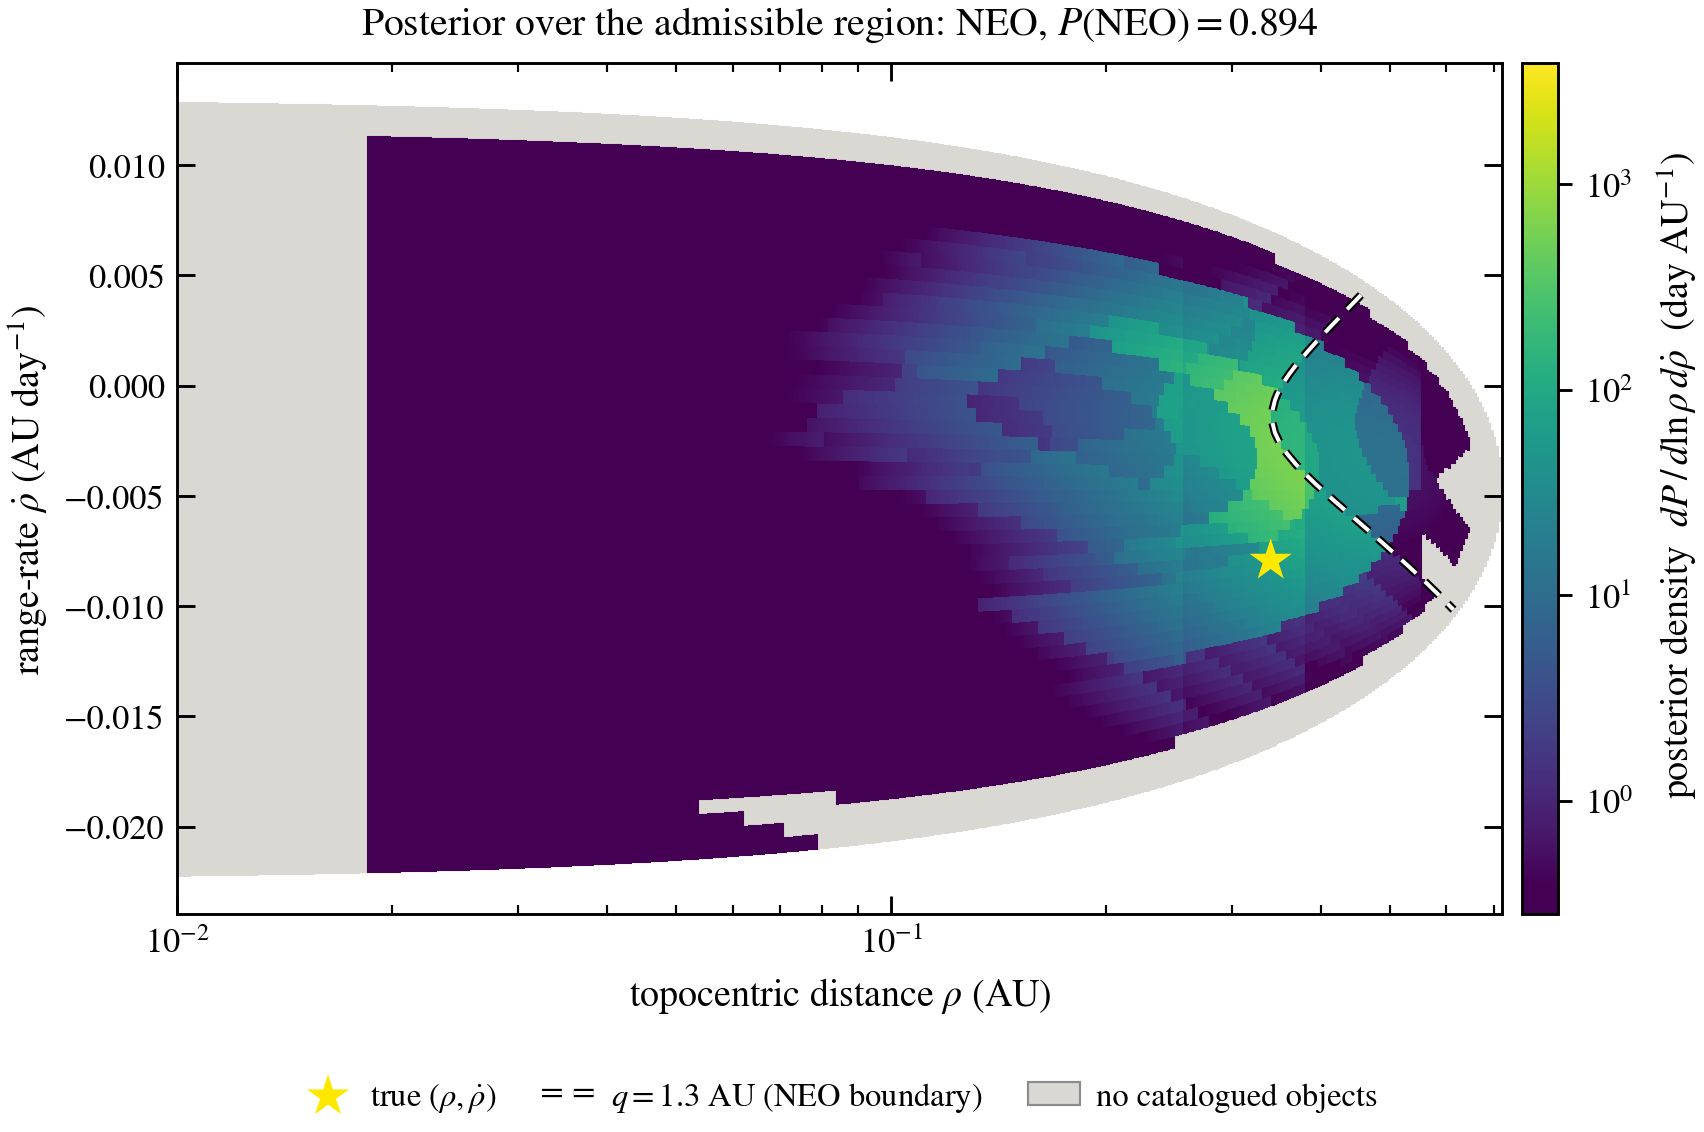

MBA: q = 1.3 AU contour has 2 branch segment(s)


wrote priora_mba_hypothesis_space.pdf/.png


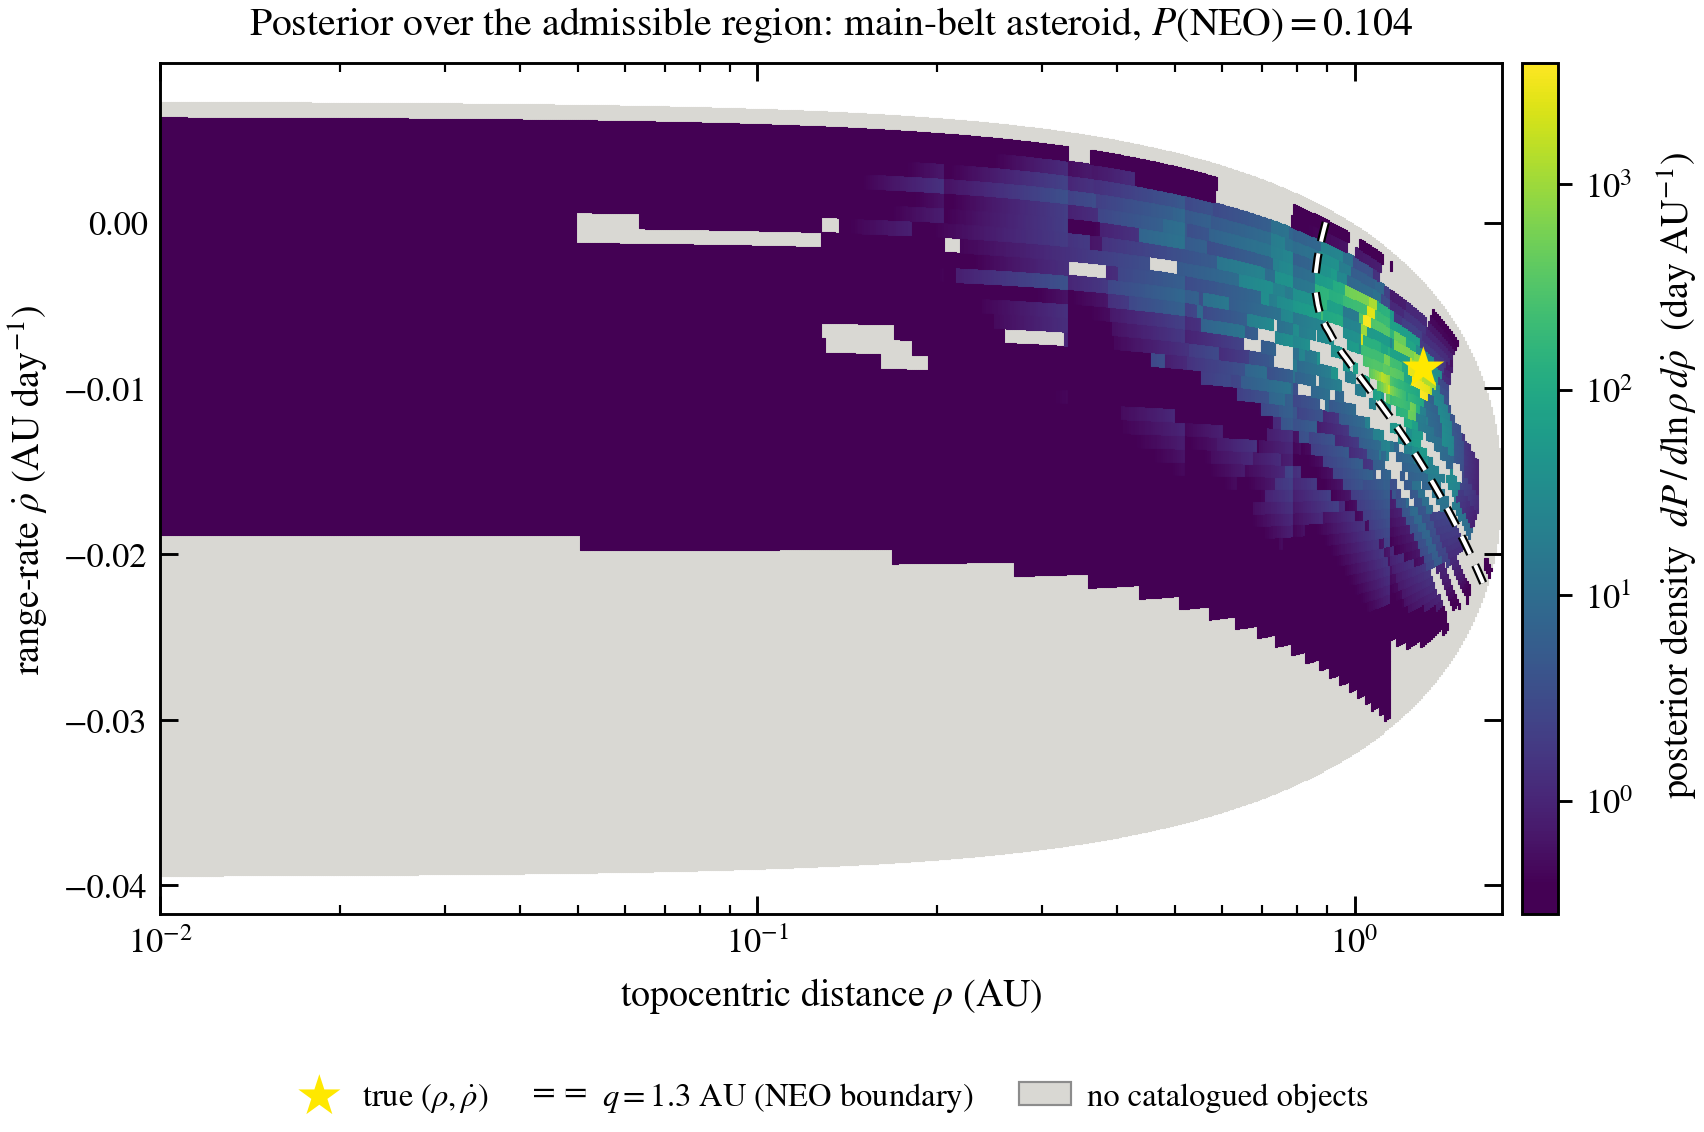

In [6]:
def q13_branches(D):
    K, cr = D["K"], D["col_rho"]
    qq, rd = D["q"].reshape(-1, K), D["rho_dot"].reshape(-1, K)
    cols = []
    for c in range(len(cr)):
        xs = []
        for j in range(K - 1):
            qa, qb = qq[c, j], qq[c, j + 1]
            if np.isfinite(qa) and np.isfinite(qb) and (qa - 1.3) * (qb - 1.3) < 0:
                xs.append(rd[c, j] + (1.3 - qa) / (qb - qa) * (rd[c, j + 1] - rd[c, j]))
        cols.append(sorted(xs))
    nb = max((len(x) for x in cols), default=0)
    out = []
    for b in range(nb):
        seg = []
        for c, xs in enumerate(cols):
            if len(xs) > b:
                seg.append((cr[c], xs[b]))
            elif seg:
                out.append(np.array(seg)); seg = []
        if seg:
            out.append(np.array(seg))
    return out

def fig_hypothesis(D):
    import matplotlib.patheffects as pe
    from matplotlib.ticker import LogLocator, LogFormatterMathtext
    fig, ax = plt.subplots(figsize=SIZE["hypothesis"], layout="constrained")
    y0, y1 = D["rho_dot"] - D["d_rhodot"] / 2, D["rho_dot"] + D["d_rhodot"] / 2
    verts = np.stack([np.c_[D["lo_e"], y0], np.c_[D["hi_e"], y0],
                      np.c_[D["hi_e"], y1], np.c_[D["lo_e"], y1]], axis=1)
    pos = D["dens"] > 0
    ax.add_collection(PolyCollection(verts[~pos], facecolors=C_NONE, edgecolors=C_NONE,
                                     linewidths=0.3, rasterized=True, zorder=1))
    norm = LogNorm(*LIM["dens"], clip=False)   # shared normalisation: colours comparable across objects
    pc = PolyCollection(verts[pos], array=D["dens"][pos], cmap=CMAP, norm=norm,
                        edgecolors="face", linewidths=0.3, rasterized=True, zorder=2)
    ax.add_collection(pc)

    # NEO boundary: thin white dashes with a thin black outline, visible on every colour
    Q13 = dict(color="white", lw=1.1, ls=(0, (5, 3)),
               path_effects=[pe.Stroke(linewidth=2.3, foreground="black"), pe.Normal()])
    branches = q13_branches(D)
    for seg in branches:
        ax.plot(seg[:, 0], seg[:, 1], zorder=4, **Q13)
    star = ax.scatter([D["truth"]["rho"]], [D["truth"]["rho_dot"]], marker="*", s=150,
                      facecolors="#FFE800", edgecolors="none", linewidths=0,
                      zorder=6, label="true $(\\rho, \\dot\\rho)$")

    ax.set_xscale("log")
    if SHARE_AXES:
        ax.set_xlim(*LIM["rho"]); ax.set_ylim(*LIM["rhodot"])
    else:
        ylo, yhi = y0.min(), y1.max(); padv = 0.05 * (yhi - ylo)
        ax.set_xlim(D["lo_e"].min(), D["hi_e"].max()); ax.set_ylim(ylo - padv, yhi + padv)
    ax.set_xlabel(r"topocentric distance $\rho$ (AU)")
    ax.set_ylabel(r"range-rate $\dot\rho$ (AU day$^{-1}$)")

    cb = fig.colorbar(pc, ax=ax, pad=0.015, fraction=0.05, aspect=24,
                      extend="min", extendfrac=0.035, extendrect=True)
    cb.set_label("posterior density  " + r"$dP\,/\,d\ln\rho\,d\dot\rho$" + "  (day AU$^{-1}$)",
                 labelpad=6)
    cb.ax.yaxis.set_major_locator(LogLocator(base=10, numticks=12))
    cb.ax.yaxis.set_major_formatter(LogFormatterMathtext())
    cb.ax.minorticks_off()
    cb.ax.tick_params(direction="out", length=4, width=0.8, right=True, left=False)
    cb.outline.set_linewidth(0.8)

    handles = [star,
               mpl.patches.Patch(facecolor=C_NONE, edgecolor="0.55", lw=0.6, label="no catalogued objects")]
    if branches:   # white dash on a dark swatch so the legend entry is visible on the white page
        handles.insert(1, mpl.lines.Line2D([], [], **Q13))
    labels = ["true $(\\rho, \\dot\\rho)$", "$q = 1.3$ AU (NEO boundary)", "no catalogued objects"]
    if not branches:
        labels.pop(1)
    from matplotlib.legend_handler import HandlerTuple
    ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=len(handles),
              frameon=False, handlelength=1.6, columnspacing=1.4, handletextpad=0.5)
    if ANNOTATE:
        ax.set_title(f"Posterior over the admissible region: {NAME[D['lab']]}, "
                     f"$P(\\mathrm{{NEO}}) = {D['res'].p_neo:.3f}$", loc="center", pad=8)
    return fig

for lab, D in DATA.items():
    nb = len(q13_branches(D))
    print(f"{lab}: q = 1.3 AU contour has {nb} branch segment(s)"
          + ("  -- none: every node implies a NEO orbit" if nb == 0 else ""))
    fig = fig_hypothesis(D); save(fig, f"priora_{lab.lower()}_hypothesis_space"); plt.show()

## 7. Orbit space — what each node implies

The same nodes, placed at the (q, e) of the orbit each implies (unbound nodes, which have no q, are omitted).
Colour is the register that holds objects at that orbit; the vertical line is the NEO definition.
Nodes are drawn in register order (neither → other → NEO) so the populated ones sit on top.

wrote priora_neo_orbit_space.pdf/.png


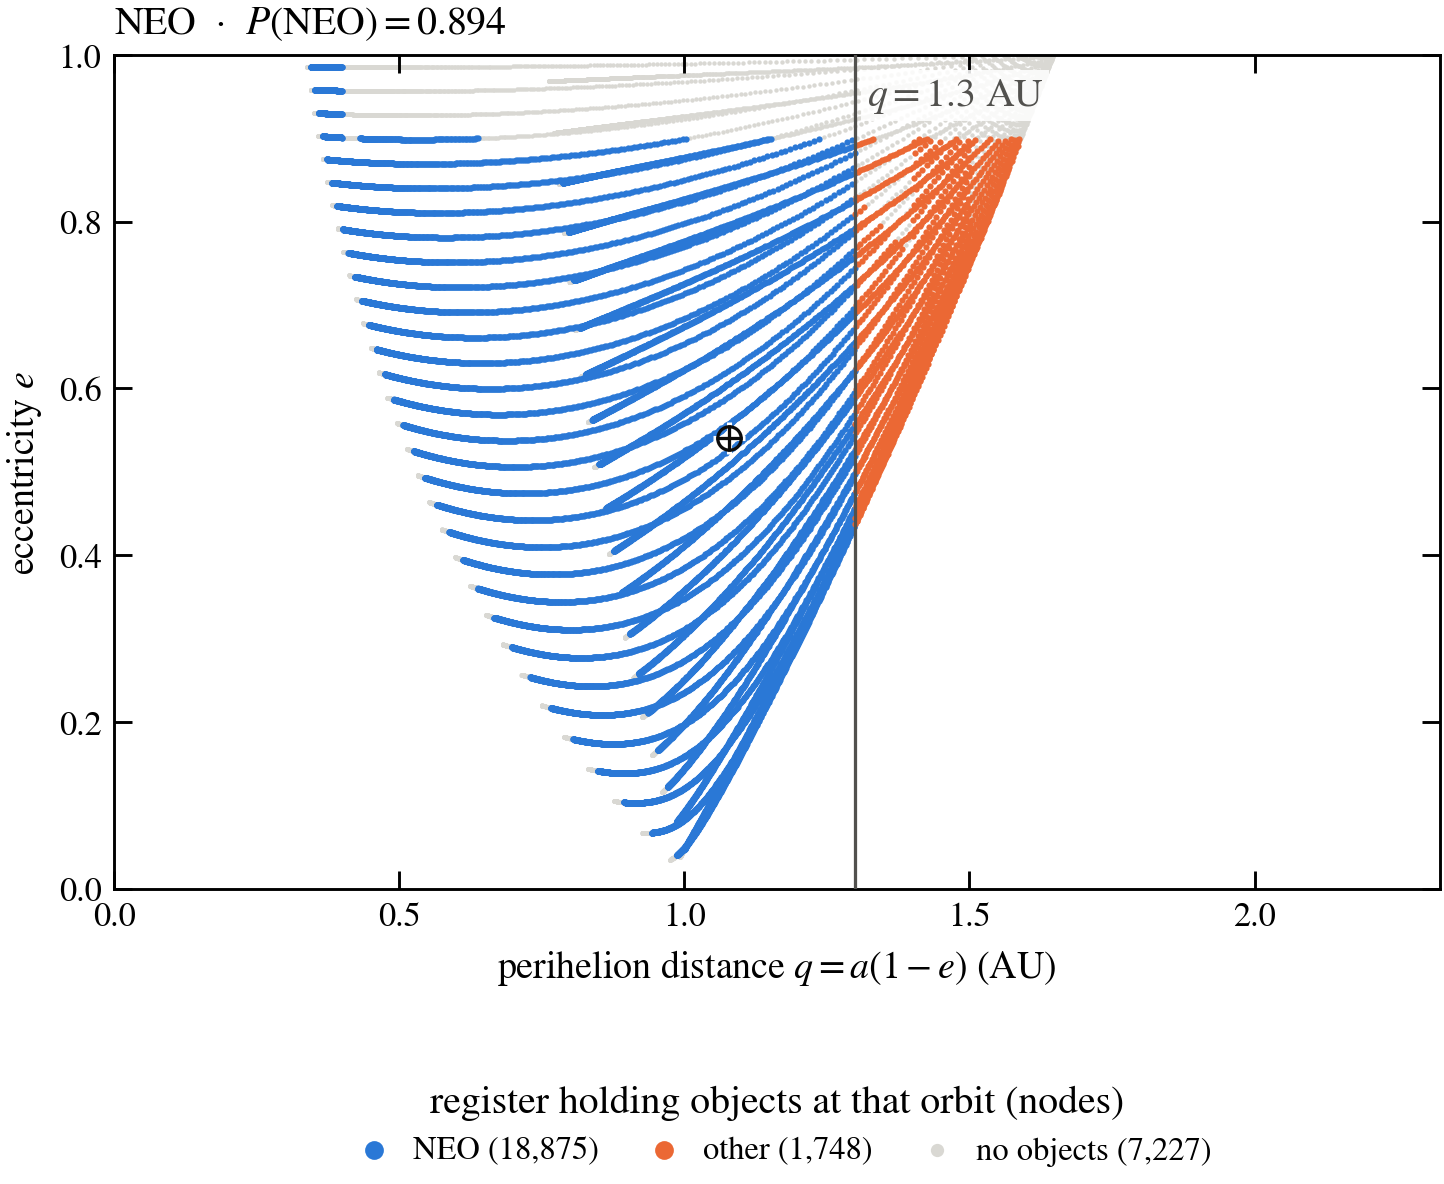

wrote priora_mba_orbit_space.pdf/.png


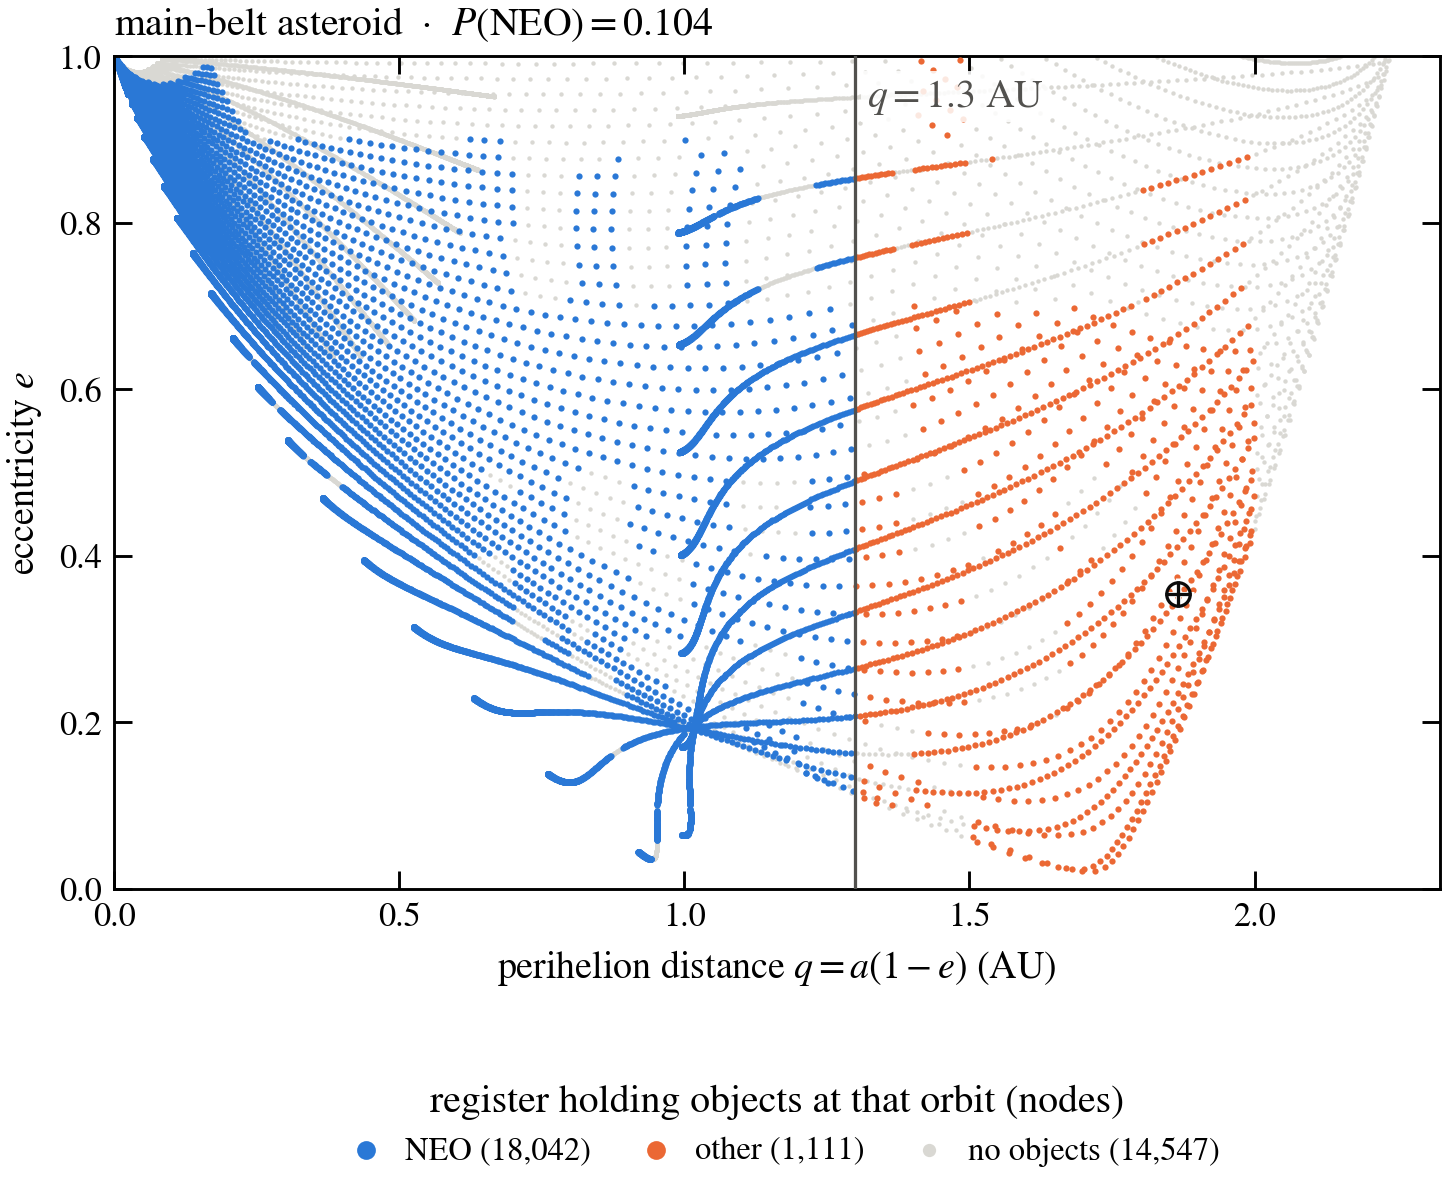

In [7]:
def fig_orbit(D):
    fig, ax = plt.subplots(figsize=SIZE["orbit"], layout="constrained")
    ok = np.isfinite(D["q"]) & np.isfinite(D["e"])
    for r, c, s, lbl in ((0, C_NONE, 1.5, "no objects"), (2, C_OTH, 3.0, "other"),
                         (1, C_NEO, 3.0, "NEO")):
        m = ok & (D["reg"] == r)
        ax.scatter(D["q"][m], D["e"][m], s=s, c=c, lw=0, rasterized=True, zorder=1 + r % 3,
                   label=f"{lbl} ({m.sum():,})")
    ax.axvline(1.3, color=C_LINE, lw=0.9, zorder=4)
    ax.text(1.32, 0.975, "$q=1.3$ AU", ha="left", va="top", fontsize=11, color=C_LINE,
            bbox=dict(boxstyle="square,pad=0.15", fc="white", ec="none", alpha=0.85), zorder=5)
    truth_marker(ax, D["truth"]["q"], D["truth"]["e"])
    ax.set_xlim(*LIM["q"]); ax.set_ylim(*LIM["e"])
    ax.set_xlabel(r"perihelion distance $q=a(1-e)$ (AU)"); ax.set_ylabel(r"eccentricity $e$")
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3,
              markerscale=3, frameon=False, handletextpad=0.2, columnspacing=1.0,
              title="register holding objects at that orbit (nodes)", title_fontsize=11)
    if ANNOTATE:   # in the title: the data fill every corner of this panel
        ax.set_title(f"{NAME[D['lab']]}  ·  $P(\\mathrm{{NEO}})={D['res'].p_neo:.3f}$", loc="left")
    return fig

for lab, D in DATA.items():
    fig = fig_orbit(D); save(fig, f"priora_{lab.lower()}_orbit_space"); plt.show()

## 8. Distance posterior — the plane collapsed onto ρ

Sum each ρ column of the hypothesis-space posterior. Because the ρ nodes are uniform in ln ρ, this is a
density per unit ln ρ, the right quantity on a log axis (area under the curve = probability).

NEO: ∫ dP/dlnρ dlnρ = 1.000000


wrote priora_neo_distance_posterior.pdf/.png


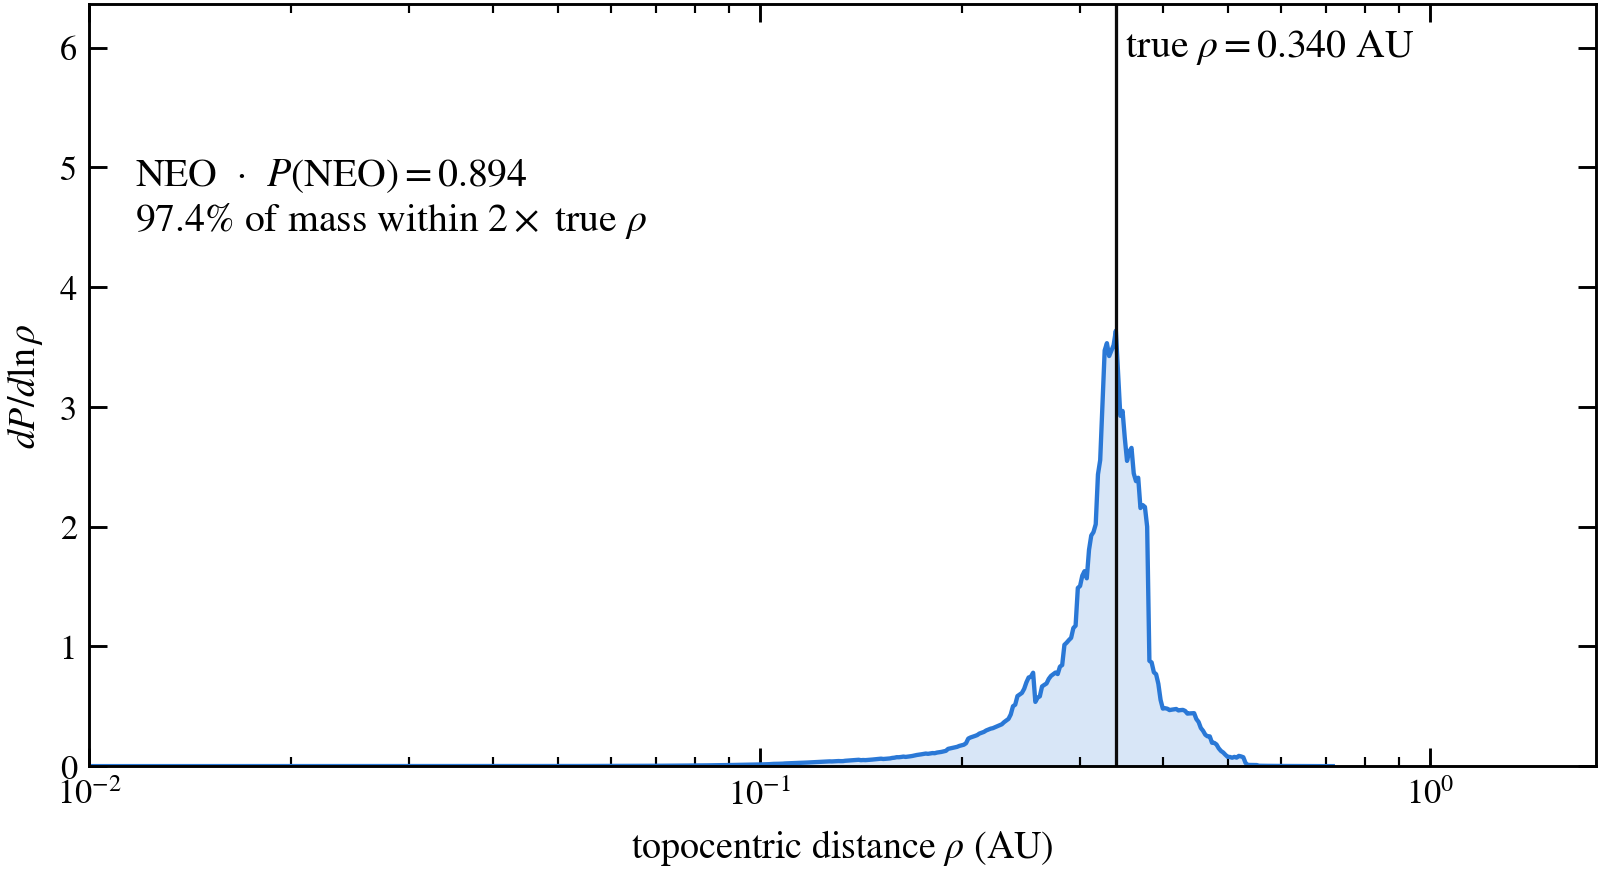

MBA: ∫ dP/dlnρ dlnρ = 1.000000


wrote priora_mba_distance_posterior.pdf/.png


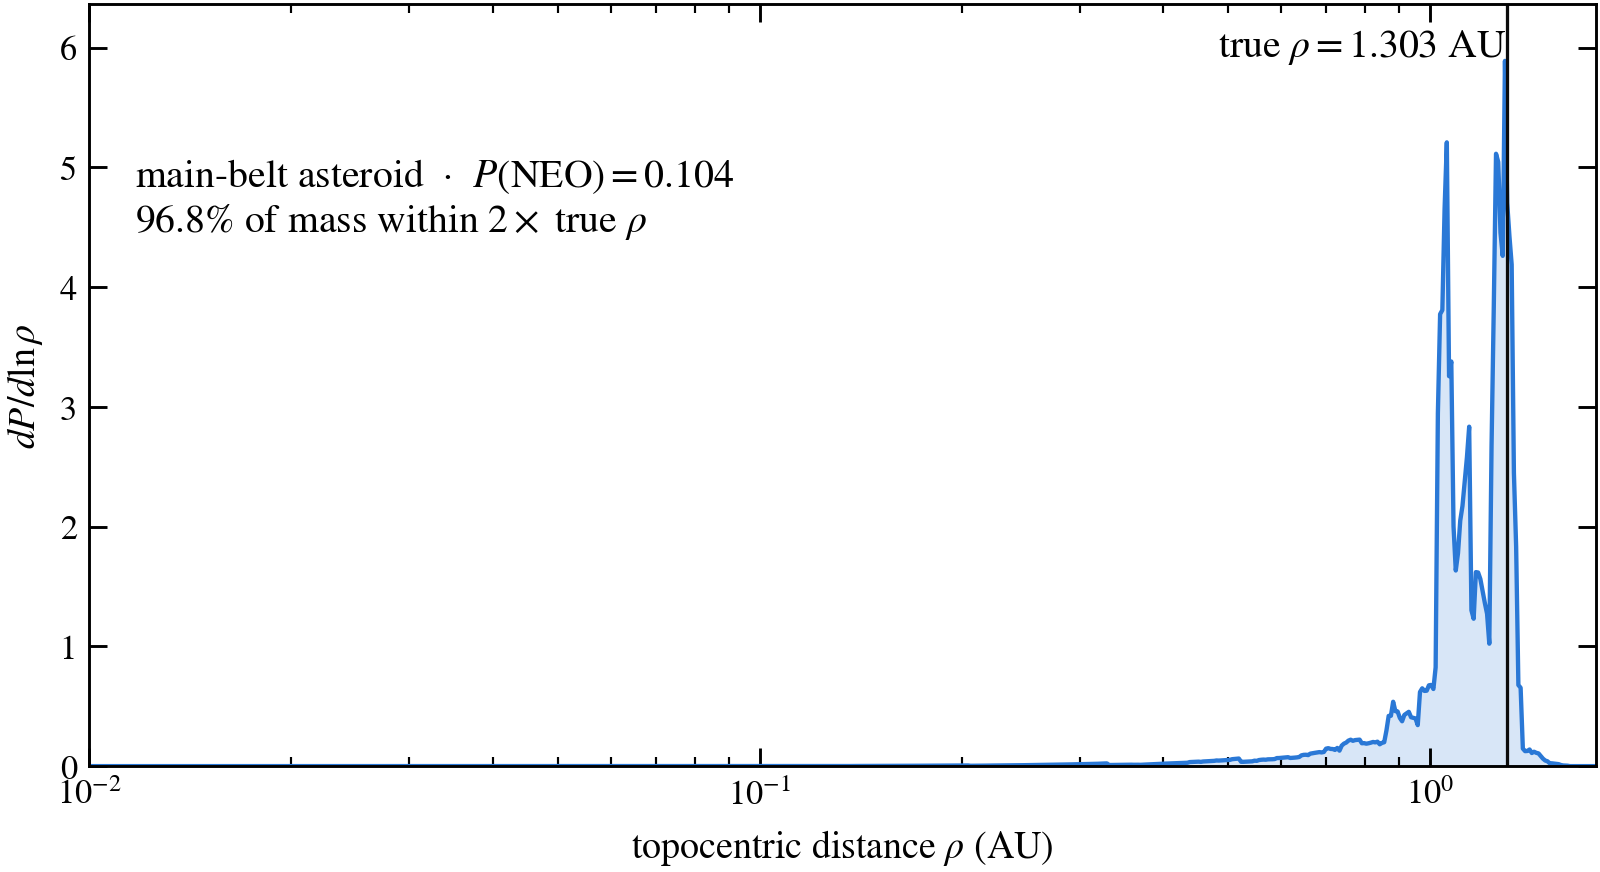

In [8]:
def fig_distance(D):
    fig, ax = plt.subplots(figsize=SIZE["distance"], layout="constrained")
    x, y = D["col_rho"], D["p_lnrho"]
    ax.fill_between(x, y, color=C_NEO, alpha=0.18, lw=0)
    ax.plot(x, y, color=C_NEO, lw=1.2)
    ax.axvline(D["truth"]["rho"], color=C_INK, lw=0.9)
    right = np.log(D["truth"]["rho"] / LIM["rho"][0]) / np.log(LIM["rho"][1] / LIM["rho"][0]) > 0.7
    ax.text(D["truth"]["rho"], LIM["plnrho"][1] * 0.97,
            (f"true $\\rho={D['truth']['rho']:.3f}$ AU " if right else f" true $\\rho={D['truth']['rho']:.3f}$ AU"),
            ha="right" if right else "left", va="top", fontsize=11)
    ax.set_xscale("log"); ax.set_xlim(*LIM["rho"]); ax.set_ylim(*LIM["plnrho"])
    ax.set_xlabel(r"topocentric distance $\rho$ (AU)"); ax.set_ylabel(r"$dP/d\ln\rho$")
    if ANNOTATE:
        ax.text(0.03, 0.80, f"{NAME[D['lab']]}  ·  $P(\\mathrm{{NEO}})={D['res'].p_neo:.3f}$\n"
                f"{D['within2']:.1%} of mass within $2\\times$ true $\\rho$",
                transform=ax.transAxes, ha="left", va="top", fontsize=11)
    return fig

for lab, D in DATA.items():
    area = np.sum(D["p_lnrho"] * np.diff(np.log(np.r_[D['lo_e'][::D['K']], D['hi_e'][::D['K']][-1:]])))
    print(f"{lab}: ∫ dP/dlnρ dlnρ = {area:.6f}")
    fig = fig_distance(D); save(fig, f"priora_{lab.lower()}_distance_posterior"); plt.show()

## 9. Provenance record and caption material

In [9]:
rec = dict(commit=COMMIT, dirty=DIRTY, model=MODEL.name, model_sha256=MODEL_SHA, obscode=OBSCODE,
           variant=VARIANT, h_extend_to=H_EXTEND_TO, grid=[N_RHO, N_RHODOT], rho_range=[RHO_MIN, RHO_MAX],
           source="validation/output/gate_v0/gen.npz (re-observed from the obscode above)",
           objects={lab: dict(gate_index=int(D["k"]), p_neo=float(D["res"].p_neo),
                              p_neo_gate_geocentric=float(sc["p_neo"][D["k"]]),
                              lambda_neo=float(D["res"].lambda_neo), lambda_other=float(D["res"].lambda_other),
                              n_nodes=int(D["res"].n_nodes), mass_within_2x_rho=float(D["within2"]),
                              **{k: float(v) for k, v in D["truth"].items()})
                    for lab, D in DATA.items()})
(OUT / "priora_example_figures_provenance.json").write_text(json.dumps(rec, indent=2))
print(json.dumps(rec, indent=2))

for lab, D in DATA.items():
    t = D["truth"]
    print(f"\n[{lab}] Gate object #{D['k']} (a = {t['a']:.3f} AU, e = {t['e']:.3f}, i = {t['i']:.1f}°, "
          f"q = {t['q']:.3f} AU, H = {t['H']:.2f}), observed from Rubin (X05) at V = {t['V']:.2f}; "
          f"P(NEO) = {D['res'].p_neo:.3f}. Production grid ({N_RHO} × {N_RHODOT}), digest2 'All' model "
          f"with H extended to {H_EXTEND_TO:g}, priora commit {COMMIT}.")

{
  "commit": "a4bc848",
  "dirty": false,
  "model": "digest2.model.csv",
  "model_sha256": "2b9d9d2a6d8ab16d3a2dbb835b30d3aa172431f27c3cb7c159675d7686668c45",
  "obscode": "X05",
  "variant": "All",
  "h_extend_to": 30.0,
  "grid": [
    1200,
    50
  ],
  "rho_range": [
    0.01,
    100.0
  ],
  "source": "validation/output/gate_v0/gen.npz (re-observed from the obscode above)",
  "objects": {
    "NEO": {
      "gate_index": 5679,
      "p_neo": 0.8940027580724615,
      "p_neo_gate_geocentric": 0.8948042620897382,
      "lambda_neo": 76070.02664179928,
      "lambda_other": 9019.22610929076,
      "n_nodes": 27850,
      "mass_within_2x_rho": 0.9740420601353024,
      "rho": 0.34042482146647046,
      "rho_dot": -0.007936791258818684,
      "a": 2.3494986372540723,
      "e": 0.5409867812834352,
      "i": 10.739620373255615,
      "q": 1.0784509318561744,
      "H": 23.285213797668206,
      "V": 22.484319510850586
    },
    "MBA": {
      "gate_index": 1247,
      "p_neo": 0.1